# 01 — Filterbank

Phase 1, step 1: design the channel-vocoder filterbank.

A CI simulation splits audio into N bandpass channels, **log-spaced** (Greenwood-style)
across roughly 200 Hz–7000 Hz, rather than linearly spaced — this matches how frequency
resolution degrades with a real cochlear implant's limited electrode count.

This notebook: load the test clips, design N log-spaced Butterworth bandpass filters,
split a signal into bands, and listen to a couple of individual bands to sanity-check
that each one isolates the frequency range it's supposed to.

In [1]:
import numpy as np
import soundfile as sf
from scipy import signal
import matplotlib.pyplot as plt
from IPython.display import Audio, display

TARGET_SR = 16000  # Nyquist = 8 kHz, comfortably above our 7 kHz band ceiling

## Load test clips

Load each clip at its native sample rate first — before any resampling — so we can compare against what resampling does to it.

In [2]:
def load_raw(path):
    audio, native_sr = sf.read(path)
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    return audio.astype(np.float32), native_sr

speech_raw, speech_native_sr = load_raw("../samples/speech.wav")
music_raw, music_native_sr = load_raw("../samples/music.wav")

print(f"speech: {len(speech_raw)/speech_native_sr:.2f}s @ {speech_native_sr} Hz (native)")
print(f"music:  {len(music_raw)/music_native_sr:.2f}s @ {music_native_sr} Hz (native)")

speech: 2.62s @ 16000 Hz (native)
music:  4.50s @ 44100 Hz (native)


## Resample to a common rate

The filterbank design applies identically to both clips only if they share a sample
rate — resample each to `TARGET_SR`. Zoom into a few milliseconds of waveform to see
what resampling actually does: fewer/more points per second, and (for a downsample
like music's 44.1 kHz → 16 kHz) a lowpass applied first so energy above the new
Nyquist can't alias back in.

In [3]:
def resample_to(audio, native_sr, target_sr):
    if native_sr == target_sr:
        return audio
    n_samples = int(len(audio) * target_sr / native_sr)
    return signal.resample(audio, n_samples).astype(np.float32)

speech = resample_to(speech_raw, speech_native_sr, TARGET_SR)
music = resample_to(music_raw, music_native_sr, TARGET_SR)
sr = TARGET_SR

print(f"speech: {len(speech)/sr:.2f}s @ {sr} Hz (resampled)")
print(f"music:  {len(music)/sr:.2f}s @ {sr} Hz (resampled)")

speech: 2.62s @ 16000 Hz (resampled)
music:  4.50s @ 16000 Hz (resampled)


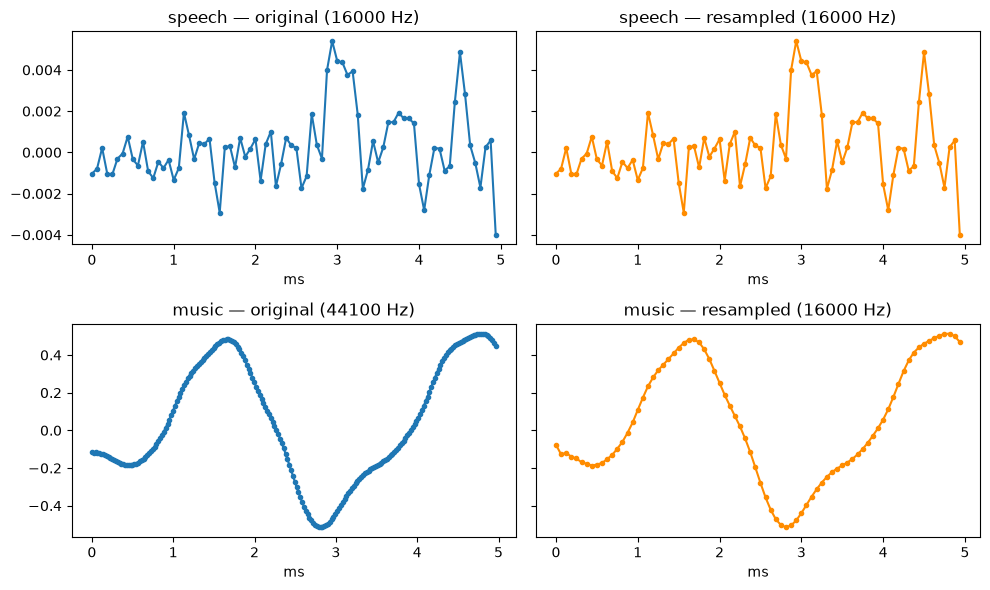

In [4]:
def plot_resample_compare(raw, raw_sr, resampled, resampled_sr, label, ax_orig, ax_resampled, window_ms=5):
    n_orig = int(raw_sr * window_ms / 1000)
    n_res = int(resampled_sr * window_ms / 1000)
    t_orig = np.arange(n_orig) / raw_sr * 1000
    t_res = np.arange(n_res) / resampled_sr * 1000

    ax_orig.plot(t_orig, raw[:n_orig], marker="o", markersize=3)
    ax_orig.set_title(f"{label} — original ({raw_sr} Hz)")
    ax_orig.set_xlabel("ms")

    ax_resampled.plot(t_res, resampled[:n_res], marker="o", markersize=3, color="darkorange")
    ax_resampled.set_title(f"{label} — resampled ({resampled_sr} Hz)")
    ax_resampled.set_xlabel("ms")

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey="row")
plot_resample_compare(speech_raw, speech_native_sr, speech, sr, "speech", axes[0, 0], axes[0, 1])
plot_resample_compare(music_raw, music_native_sr, music, sr, "music", axes[1, 0], axes[1, 1])
plt.tight_layout()
plt.show()

Listen to the originals before doing anything else to them.

In [5]:
display(Audio(speech, rate=sr))
display(Audio(music, rate=sr))

## Design the filterbank

N log-spaced bandpass filters spanning `f_min`–`f_max`. Band edges are spaced evenly
in log-frequency (a simple log spacing — not the full Greenwood function, but it
captures the key property: narrower bands at low frequencies, wider bands at high
frequencies). Butterworth, zero-phase via `sosfiltfilt`.

In [6]:
def design_filterbank(n_channels, sr, f_min=200, f_max=7000, order=4):
    """Return (sos_list, edges, centers) for N log-spaced Butterworth bandpass filters."""
    edges = np.logspace(np.log10(f_min), np.log10(f_max), n_channels + 1)
    centers = np.sqrt(edges[:-1] * edges[1:])  # geometric mean = center freq per band

    nyquist = sr / 2
    sos_list = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sos = signal.butter(order, [lo / nyquist, hi / nyquist], btype="bandpass", output="sos")
        sos_list.append(sos)

    return sos_list, edges, centers

N_CHANNELS = 8  # start here per the build plan; parameterize once this looks right
filterbank, edges, centers = design_filterbank(N_CHANNELS, sr)

for i, (lo, hi, c) in enumerate(zip(edges[:-1], edges[1:], centers)):
    print(f"band {i}: {lo:7.1f}–{hi:7.1f} Hz  (center {c:7.1f} Hz)")

band 0:   200.0–  311.9 Hz  (center   249.8 Hz)
band 1:   311.9–  486.5 Hz  (center   389.5 Hz)
band 2:   486.5–  758.7 Hz  (center   607.5 Hz)
band 3:   758.7– 1183.2 Hz  (center   947.5 Hz)
band 4:  1183.2– 1845.3 Hz  (center  1477.6 Hz)
band 5:  1845.3– 2877.9 Hz  (center  2304.5 Hz)
band 6:  2877.9– 4488.4 Hz  (center  3594.1 Hz)
band 7:  4488.4– 7000.0 Hz  (center  5605.2 Hz)


Plot each band's frequency response to confirm the bands are correctly placed and don't leave gaps or excessive overlap.

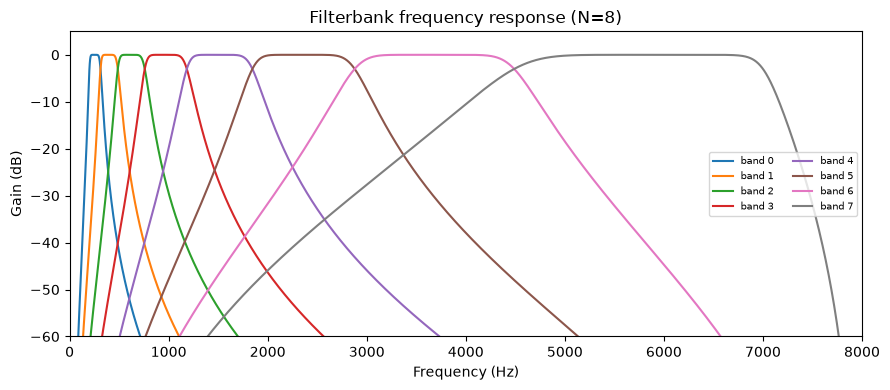

In [7]:
plt.figure(figsize=(9, 4))
for i, sos in enumerate(filterbank):
    w, h = signal.sosfreqz(sos, worN=2048, fs=sr)
    plt.plot(w, 20 * np.log10(np.maximum(np.abs(h), 1e-6)), label=f"band {i}")

plt.xlim(0, sr / 2)
plt.ylim(-60, 5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Gain (dB)")
plt.title(f"Filterbank frequency response (N={N_CHANNELS})")
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## Split a signal into bands

Apply each bandpass filter to the full signal with `sosfiltfilt` (zero-phase, so bands
stay time-aligned with each other — important later when we recombine them).

In [8]:
def split_into_bands(audio, sos_list):
    return [signal.sosfiltfilt(sos, audio) for sos in sos_list]

speech_bands = split_into_bands(speech, filterbank)
music_bands = split_into_bands(music, filterbank)

print(f"{len(speech_bands)} bands, each {len(speech_bands[0])} samples")

8 bands, each 41920 samples


## Sanity check: listen to individual bands

The lowest band should sound like a dull rumble; the highest band should sound thin
and hissy/sibilant. If a band sounds like it's leaking most of the original signal's
energy, the filter design is off — check the edges above before moving on.

In [9]:
print("speech — lowest band (~band 0):")
display(Audio(speech_bands[0], rate=sr))

print(f"speech — highest band (~band {N_CHANNELS - 1}):")
display(Audio(speech_bands[-1], rate=sr))

speech — lowest band (~band 0):


speech — highest band (~band 7):


Confirm spectrally too: each band's energy should sit between its designed edges (dashed lines).

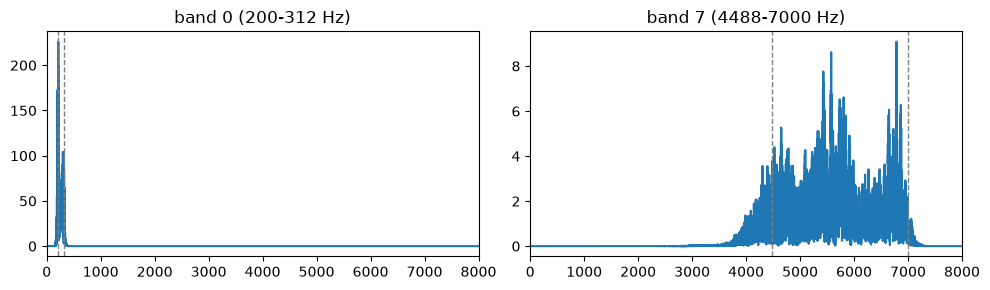

In [10]:
def plot_band_spectrum(band_signal, lo, hi, sr, ax):
    freqs = np.fft.rfftfreq(len(band_signal), d=1 / sr)
    mag = np.abs(np.fft.rfft(band_signal))
    ax.plot(freqs, mag)
    ax.axvline(lo, color="gray", linestyle="--", linewidth=1)
    ax.axvline(hi, color="gray", linestyle="--", linewidth=1)
    ax.set_xlim(0, sr / 2)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
plot_band_spectrum(speech_bands[0], edges[0], edges[1], sr, axes[0])
axes[0].set_title(f"band 0 ({edges[0]:.0f}-{edges[1]:.0f} Hz)")
plot_band_spectrum(speech_bands[-1], edges[-2], edges[-1], sr, axes[1])
axes[1].set_title(f"band {N_CHANNELS - 1} ({edges[-2]:.0f}-{edges[-1]:.0f} Hz)")
plt.tight_layout()
plt.show()